# L18 · RAG conversacional: reformular antes de recuperar

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

En [L4](L4-RAG.ipynb) el asistente de **ACME** respondía preguntas sobre las políticas citando documento y página. Pero un cliente no hace una sola pregunta: escribe *«Tengo 45 días de mora en mi Crédito Libre Inversión, ¿puedo reestructurarlo?»* y enseguida añade **«¿Y cuántas veces puedo hacerlo?»**. Esa segunda pregunta solo tiene sentido con la primera.

El modelo puede leer el historial, pero **el retriever no**: busca con el texto exacto que recibe. Hoy transformamos la pregunta antes de recuperar, primero **reformulándola** con el historial y después generando **varias versiones** de una pregunta coloquial. Al final medimos la recuperación con las 22 preguntas de `datasets/acme_questions.csv`.

## Qué construimos

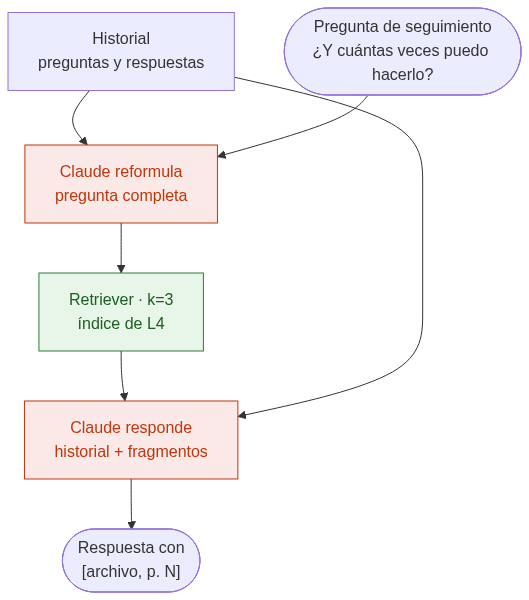

<details><summary>Código Mermaid</summary>

```mermaid
flowchart TB
    H["Historial<br/>preguntas y respuestas"] --> RW
    Q(["Pregunta de seguimiento<br/>¿Y cuántas veces puedo hacerlo?"]) --> RW["Claude reformula<br/>pregunta completa"]
    RW --> R["Retriever · k=3<br/>índice de L4"]
    R --> M["Claude responde<br/>historial + fragmentos"]
    H --> M
    M --> A(["Respuesta con<br/>[archivo, p. N]"])

    classDef local fill:#e8f5e9,stroke:#2e7d32,color:#1b5e20
    classDef claude fill:#fbe9e7,stroke:#bf360c,color:#bf360c
    class R local
    class RW,M claude
```

</details>

En verde lo que corre en tu equipo; en naranja, las llamadas a Claude. Reformular añade **una llamada** por pregunta.

## Objetivos

Al terminar podrás:

1. Explicar por qué una pregunta de seguimiento recupera fragmentos equivocados.
2. Representar el historial como una lista de mensajes.
3. Reformular la pregunta con el historial antes de recuperar, en una cadena con `@chain`, y pasar el historial a la respuesta con `MessagesPlaceholder`.
4. Generar varias consultas con salida estructurada y unir lo que recuperan.
5. Comprobar que la cadena conversacional sigue diciendo «no está» cuando los documentos no responden.
6. Medir la recuperación con un conjunto de preguntas y comparar coseno, BM25 y su fusión con RRF.

## Contenido

- [0. Preparación de los modelos](#0.-Preparación-de-los-modelos)
- [1. El índice de L4](#1.-El-índice-de-L4)
- [2. Una pregunta de seguimiento](#2.-Una-pregunta-de-seguimiento)
- [3. Reformular la pregunta](#3.-Reformular-la-pregunta)
- [4. La cadena conversacional](#4.-La-cadena-conversacional)
- [5. Varias consultas para una pregunta coloquial](#5.-Varias-consultas-para-una-pregunta-coloquial)
- [6. Una pregunta sin respuesta en la conversación](#6.-Una-pregunta-sin-respuesta-en-la-conversación)
- [7. Lo que cuesta cada estrategia](#7.-Lo-que-cuesta-cada-estrategia)
- [8. Medir la recuperación: coseno, BM25 y RRF](#8.-Medir-la-recuperación:-coseno,-BM25-y-RRF)
- [Práctica breve](#Práctica-breve)
- [Referencias](#Referencias)

El recorrido realiza **8 llamadas a Claude Haiku**, en las secciones 2 a 6. La sección 8 no llama a ningún modelo. Repetir celdas consume tokens.

## 0. Preparación de los modelos

Los mismos dos modelos de L4: Claude Haiku para reformular y responder, y el modelo abierto de embeddings.

LangSmith es opcional: con `LANGSMITH_TRACING=true`, las secciones 2 a 6 generan **11 trazas**: una por cada `invoke` y cuatro de `retriever.batch` en la sección 5, que crea una por consulta. La sección 8 desactiva las trazas.

In [ ]:
import os

from dotenv import find_dotenv, load_dotenv
from langchain_anthropic import ChatAnthropic
from langchain_community.embeddings import FastEmbedEmbeddings

# find_dotenv sube por las carpetas hasta encontrar el .env de la raíz
load_dotenv(find_dotenv())

model = ChatAnthropic(
    model="claude-haiku-5-5",
    max_tokens=500,
    thinking={"type": "disabled"},
    timeout=60,
    max_retries=2,
)
# Modelo abierto y multilingüe: corre en este equipo, sin API key ni costo por uso.
embeddings = FastEmbedEmbeddings(model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
print("Trazas en LangSmith:", os.getenv("LANGSMITH_TRACING", "false"))

## 1. El índice de L4

Sin modelo. Repetimos en una celda lo que en L3 y L4 tomó varias secciones: cargar los PDFs con su archivo y página, fragmentarlos, guardarlos en `InMemoryVectorStore` y crear el retriever con `k=3`. `format_docs` arma el contexto con el formato `[archivo, p. N]`.

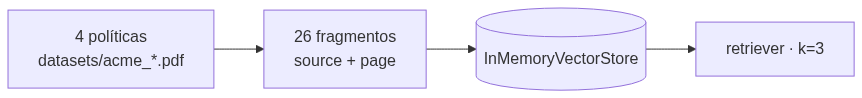

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    D["4 políticas<br/>datasets/acme_*.pdf"] --> F["26 fragmentos<br/>source + page"]
    F --> I[("InMemoryVectorStore")]
    I --> R["retriever · k=3"]
```

</details>

In [ ]:
from pathlib import Path

from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pypdf import PdfReader

pages = []
for path in sorted(Path("../datasets").glob("acme_*.pdf")):
    for number, page in enumerate(PdfReader(path).pages, 1):
        pages.append(Document(page.extract_text(), metadata={"source": path.name, "page": number}))

chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=60).split_documents(pages)
vector_store = InMemoryVectorStore.from_documents(chunks, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 3})


def format_docs(docs):
    return "\n\n".join(f"[{doc.metadata['source']}, p. {doc.metadata['page']}]\n{doc.page_content}" for doc in docs)


print(len(pages), "páginas →", len(chunks), "fragmentos")

La cadena `rag` de L4, sin cambios: recupera con la pregunta, arma el contexto y responde con el mismo *system prompt*.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import chain

SYSTEM_PROMPT = """\
Eres el asistente de soporte de ACME, una fintech.
Responde solo con la información de los fragmentos de documentos que recibes.
Después de cada dato, cita su fuente con el formato [archivo, p. N], tal como aparece en el fragmento.
Si los fragmentos no contienen la respuesta, o solo una parte, di qué no está en los documentos consultados y no lo inventes.
No prometas aprobaciones ni des asesoría financiera personalizada.
"""

prompt = ChatPromptTemplate.from_messages(
    [("system", SYSTEM_PROMPT), ("human", "Fragmentos:\n\n{context}\n\nPregunta: {question}")]
)


@chain
def rag(question: str):
    docs = retriever.invoke(question)
    return model.invoke(prompt.format_messages(context=format_docs(docs), question=question))

## 2. Una pregunta de seguimiento

Empieza la conversación. La primera pregunta es completa: tiene el producto, la situación y lo que se quiere saber. `rag` la responde como en L4 (**1 llamada**).

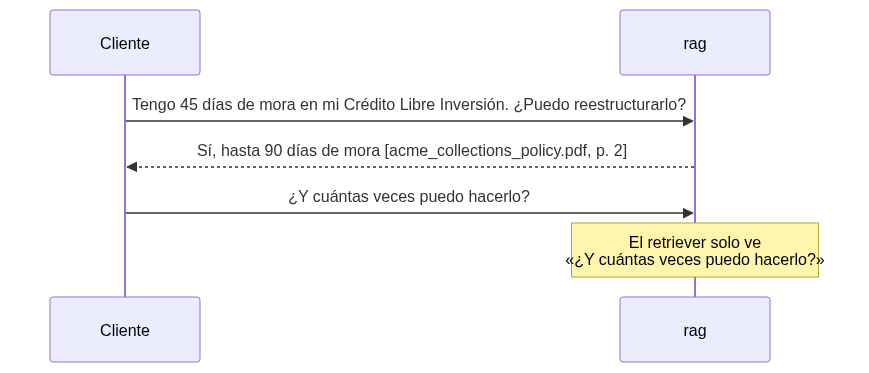

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant U as Cliente
    participant A as rag
    U->>A: Tengo 45 días de mora en mi Crédito Libre Inversión. ¿Puedo reestructurarlo?
    A-->>U: Sí, hasta 90 días de mora [acme_collections_policy.pdf, p. 2]
    U->>A: ¿Y cuántas veces puedo hacerlo?
    Note over A: El retriever solo ve<br/>«¿Y cuántas veces puedo hacerlo?»
```

</details>

In [ ]:
first_question = "Tengo 45 días de mora en mi Crédito Libre Inversión. ¿Puedo reestructurarlo?"
first_answer = rag.invoke(first_question)
print(first_answer.text)

La segunda pregunta depende de la primera: «hacerlo» es reestructurar el crédito. Veamos qué recupera el retriever con esa pregunta sola, **sin llamar a Claude**.

In [ ]:
follow_up = "¿Y cuántas veces puedo hacerlo?"

for doc, score in vector_store.similarity_search_with_score(follow_up, k=3):
    print(f"{score:.3f}  {doc.metadata['source']} p. {doc.metadata['page']}")
    print("      ", doc.page_content[:90].replace("\n", " "), "...")

Ninguno de los tres fragmentos es la página 2 de la política de cobranza, que dice que «cada crédito admite una sola reestructuración por año». El primero habla de la validación biométrica que «falla tres veces»: comparte la idea de *cuántas veces*, no el tema. Los puntajes, además, son bajos frente a los de L4. Con estos fragmentos, la mejor respuesta posible de Claude es «no está en los documentos»… aunque sí está.

## 3. Reformular la pregunta

Learning LangChain llama a esta técnica *rewrite-retrieve-read*: antes de recuperar, el modelo **reescribe** la pregunta. Aquí le damos también el historial, para que la pregunta reescrita se entienda sola.

El historial es una lista de mensajes: la pregunta del usuario (`HumanMessage`) y la respuesta del modelo (`AIMessage`). Para reformular, lo pasamos **como texto** dentro de un solo mensaje: si se lo pasáramos como mensajes, Claude seguiría la conversación y **respondería** la pregunta en lugar de reescribirla.

**Tuplas o clases de mensajes.** Dentro de `ChatPromptTemplate.from_messages` usamos tuplas como `("human", "... {question}")`: son **plantillas**, y LangChain reemplaza las `{variables}` al rellenarlas. Un `HumanMessage("...")` dentro de la plantilla se copia tal cual, sin reemplazar nada. Fuera de las plantillas, cuando el mensaje ya está escrito, usamos las clases `HumanMessage`, `AIMessage` y `SystemMessage`.

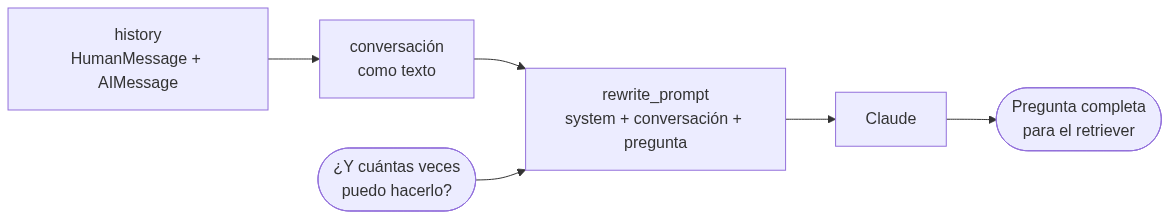

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    H["history<br/>HumanMessage + AIMessage"] --> T["conversación<br/>como texto"] --> P["rewrite_prompt<br/>system + conversación + pregunta"]
    Q(["¿Y cuántas veces<br/>puedo hacerlo?"]) --> P
    P --> M["Claude"] --> S(["Pregunta completa<br/>para el retriever"])
```

</details>

In [ ]:
from langchain_core.messages import HumanMessage

REWRITE_PROMPT = """\
Reescribe la última pregunta del usuario como una pregunta completa que se entienda sin leer la conversación.
Se usará para buscar en las políticas de crédito, desembolsos, costos y cobranza de ACME.
Incluye el producto, la situación del cliente, los montos y los plazos de la conversación a los que se refiere la pregunta.
No respondas la pregunta. Devuelve solo la pregunta reescrita.
"""

rewrite_prompt = ChatPromptTemplate.from_messages(
    [("system", REWRITE_PROMPT), ("human", "Conversación:\n{conversation}\n\nÚltima pregunta: {question}")]
)
history = [HumanMessage(first_question), first_answer]


def format_history(history):
    return "\n".join(f"{message.type}: {message.text}" for message in history)

In [ ]:
standalone_question = model.invoke(
    rewrite_prompt.format_messages(conversation=format_history(history), question=follow_up)
).text
print(standalone_question)

Con la pregunta reescrita, el mismo retriever, sin Claude:

In [ ]:
for doc, score in vector_store.similarity_search_with_score(standalone_question, k=3):
    print(f"{score:.3f}  {doc.metadata['source']} p. {doc.metadata['page']}")
    print("      ", doc.page_content[:90].replace("\n", " "), "...")

Ahora la página 2 de la política de cobranza aparece entre los tres, con un puntaje mucho más alto que con la pregunta sola. No queda necesariamente primera: el derecho de retracto también habla de plazos y créditos. **El retriever no cambió: cambió la pregunta que recibe.** Reformular es encadenar dos prompts: la salida del primero es la entrada de la recuperación.

## 4. La cadena conversacional

Juntamos los pasos en una cadena con `@chain`, como `rag` en L4. Recibe la pregunta y el historial; reformula, recupera y responde. El prompt de la respuesta sí lleva el historial **como mensajes**, para que Claude sepa de qué se viene hablando: `MessagesPlaceholder("history")` reserva su lugar entre el *system prompt* y la pregunta nueva. Devuelve un diccionario con la pregunta reescrita, los fragmentos y la respuesta, para poder revisarlos.

Cada pregunta cuesta ahora **2 llamadas**: reformular y responder.

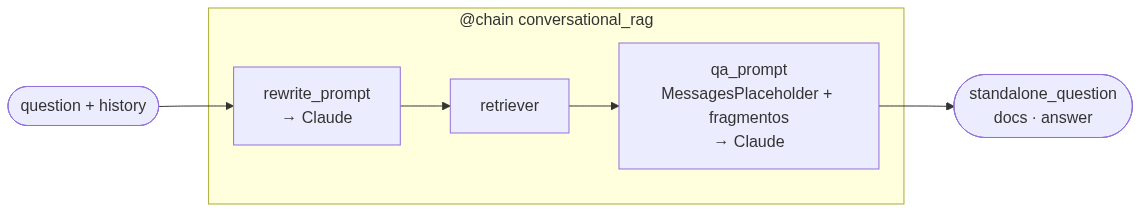

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    subgraph CR ["@chain conversational_rag"]
        RW["rewrite_prompt<br/>→ Claude"] --> R["retriever"] --> M["qa_prompt<br/>MessagesPlaceholder + fragmentos<br/>→ Claude"]
    end
    IN(["question + history"]) --> RW
    M --> OUT(["standalone_question<br/>docs · answer"])
```

</details>

In [ ]:
from langchain_core.prompts import MessagesPlaceholder

qa_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", SYSTEM_PROMPT),
        MessagesPlaceholder("history"),
        ("human", "Fragmentos:\n\n{context}\n\nPregunta: {question}"),
    ]
)


@chain
def conversational_rag(inputs: dict):
    question, history = inputs["question"], inputs["history"]
    conversation = format_history(history)
    standalone_question = model.invoke(rewrite_prompt.format_messages(conversation=conversation, question=question)).text
    docs = retriever.invoke(standalone_question)
    answer = model.invoke(qa_prompt.format_messages(history=history, context=format_docs(docs), question=question))
    return {"standalone_question": standalone_question, "docs": docs, "answer": answer}

In [ ]:
result = conversational_rag.invoke({"question": follow_up, "history": history})

print("Pregunta reescrita:", result["standalone_question"])
print("Fragmentos:", [(doc.metadata["source"], doc.metadata["page"]) for doc in result["docs"]])
print()
print(result["answer"].text)

history += [HumanMessage(follow_up), result["answer"]]

La última línea guarda el turno en `history`: la próxima pregunta verá las dos anteriores. Por ahora el historial es una lista de Python que manejamos a mano. En [L9](L9-Memory.ipynb) lo guarda LangGraph, separado por conversación.

## 5. Varias consultas para una pregunta coloquial

Reformular resuelve las referencias a la conversación. Hay otro problema: las palabras del cliente no son las del documento. Learning LangChain propone *multi-query*: pedir al modelo **varias versiones** de la pregunta, recuperar con cada una y unir los fragmentos sin repetirlos.

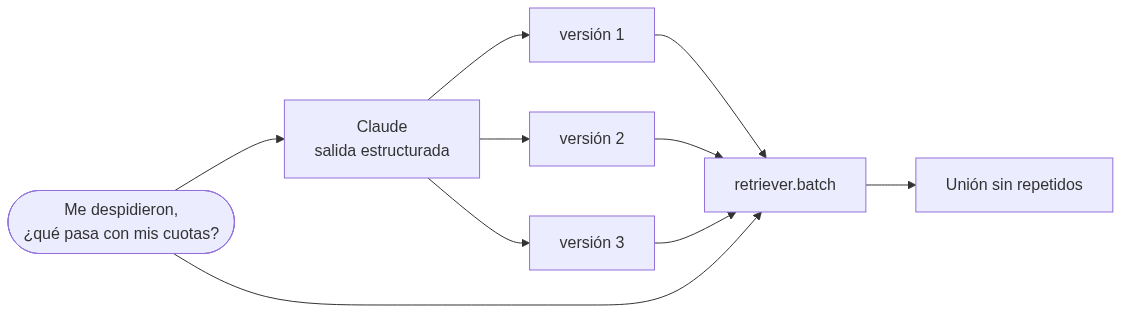

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    Q(["Me despidieron,<br/>¿qué pasa con mis cuotas?"]) --> M["Claude<br/>salida estructurada"]
    M --> Q1["versión 1"] & Q2["versión 2"] & Q3["versión 3"]
    Q1 & Q2 & Q3 & Q --> B["retriever.batch"]
    B --> U["Unión sin repetidos"]
```

</details>

Primero, lo que recupera la pregunta original, sin Claude:

In [ ]:
colloquial_question = "Me despidieron, ¿qué pasa con mis cuotas?"

single_docs = retriever.invoke(colloquial_question)
[(doc.metadata["source"], doc.metadata["page"]) for doc in single_docs]

La respuesta está en la política de cobranza, página 2: «si el cliente pierde su empleo, puede pedir un periodo de gracia de hasta 3 meses en el pago de capital». El cliente dice «me despidieron» y «cuotas»; el documento dice «pierde su empleo» y «periodo de gracia». Generamos las versiones con **salida estructurada**, como en L1 y L12: una lista de textos, sin tener que partir la respuesta por líneas (**1 llamada**).

In [ ]:
from langchain_core.messages import SystemMessage
from pydantic import BaseModel, Field

MULTI_QUERY_PROMPT = """\
Genera 3 versiones distintas de la pregunta del usuario para buscar en las políticas de crédito, desembolsos, costos y cobranza de ACME.
Cada versión es una pregunta corta, de una sola idea, con otras palabras: por ejemplo, el término formal de la situación \
(mora, desempleo, pago anticipado) o la acción que se quiere saber (reestructurar, pausar, reportar).
Así se compensan las limitaciones de la búsqueda por similitud.
"""


class SearchQueries(BaseModel):
    """Versiones de una pregunta para buscar en los documentos."""

    queries: list[str] = Field(description="Tres versiones distintas de la pregunta.")


query_model = model.with_structured_output(SearchQueries)
queries = query_model.invoke([SystemMessage(MULTI_QUERY_PROMPT), HumanMessage(colloquial_question)]).queries
queries

In [ ]:
document_lists = retriever.batch([colloquial_question, *queries])
# Un mismo fragmento puede llegar por varias consultas: se queda una sola vez.
union_docs = list({doc.page_content: doc for docs in document_lists for doc in docs}.values())

print("Una consulta:", len(single_docs), "fragmentos")
print("Varias consultas:", len(union_docs), "fragmentos")
[(doc.metadata["source"], doc.metadata["page"]) for doc in union_docs]

¿Aparece ahora la política de cobranza, página 2? Llega por las versiones que dicen «desempleado» o «sin empleo», más cerca de las palabras del documento. El precio: más del doble de fragmentos. Respondemos con la unión (**1 llamada**) y revisamos si la respuesta menciona el periodo de gracia de hasta 3 meses:

In [ ]:
multi_answer = model.invoke(prompt.format_messages(context=format_docs(union_docs), question=colloquial_question))
print(multi_answer.text)

Multi-query no garantiza el fragmento correcto y siempre trae más contexto: más tokens en la respuesta y más ruido para el modelo. Si la página 2 de cobranza no llegó, la respuesta debería decir que los fragmentos no lo cubren, y eso también es un buen resultado: no inventó. Cuando ninguna versión de la pregunta lo encuentra, conviene revisar la fragmentación o combinar con BM25, como en la sección 8.

## 6. Una pregunta sin respuesta en la conversación

En L4 la regla «si no está, dilo» funcionaba con una pregunta suelta. En una conversación hay un riesgo nuevo: el historial ya habla del crédito y de la reestructuración, y el modelo podría completar con lo que «suena» razonable. Probamos una pregunta sobre la tarjeta de crédito, que las políticas no cubren (**2 llamadas**).

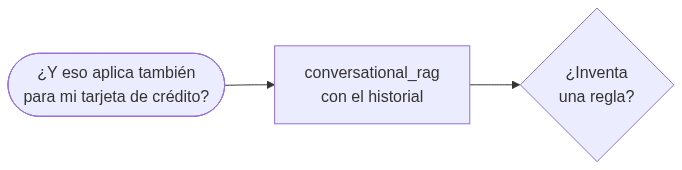

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    Q(["¿Y eso aplica también<br/>para mi tarjeta de crédito?"]) --> CR["conversational_rag<br/>con el historial"]
    CR --> A{"¿Inventa<br/>una regla?"}
```

</details>

In [ ]:
card_result = conversational_rag.invoke({"question": "¿Y eso aplica también para mi tarjeta de crédito?", "history": history})

print("Pregunta reescrita:", card_result["standalone_question"])
print()
print(card_result["answer"].text)

La pregunta reescrita debería nombrar la tarjeta de crédito. ¿La respuesta dice que las políticas no hablan de tarjetas, o supone que la regla aplica? Mira también si agrega consejos que nadie pidió, como «conviene actuar pronto»: el historial de mora empuja al modelo a seguir con el tema anterior, aunque el *system prompt* pide no dar asesoría personalizada. Ese tipo de deriva es lo que mediremos en la semana 6.

## 7. Lo que cuesta cada estrategia

Sin código. Cada técnica de hoy mejora un caso y añade llamadas:

| Estrategia | Llamadas por pregunta | Qué resuelve | Riesgo |
|---|---|---|---|
| RAG de L4 | 1 | Preguntas completas | Falla con «eso», «y si…» |
| Reformular con historial | 2 | Preguntas de seguimiento | La reformulación puede cambiar la intención |
| Multi-query | 2 | Palabras distintas a las del documento | Más fragmentos, más tokens y más ruido |

Una aplicación real puede reformular solo cuando hay historial, o usar multi-query solo cuando la recuperación tiene puntajes bajos. Esas decisiones se toman midiendo, que es lo que hacemos a continuación.

## 8. Medir la recuperación: coseno, BM25 y RRF

Sin modelo y sin trazas. Hasta ahora juzgamos la recuperación pregunta por pregunta. `datasets/acme_questions.csv` trae 22 preguntas con el **archivo y la página** donde está la respuesta; tres no tienen respuesta en los documentos. Medimos el **acierto en el top 3** (*hit rate*): una pregunta acierta si alguno de los tres fragmentos recuperados viene de la página esperada.

Comparamos tres recuperadores:

- **Coseno**: el índice vectorial de siempre, que busca por significado.
- **BM25**: búsqueda por palabras, como un buscador clásico. Premia los términos exactos y raros, como «codeudor».
- **RRF** (*Reciprocal Rank Fusion*): une las dos listas. Cada fragmento suma `1 / (60 + posición)` en cada lista donde aparece; ganan los que están arriba en ambas. Es la **búsqueda híbrida** más simple.

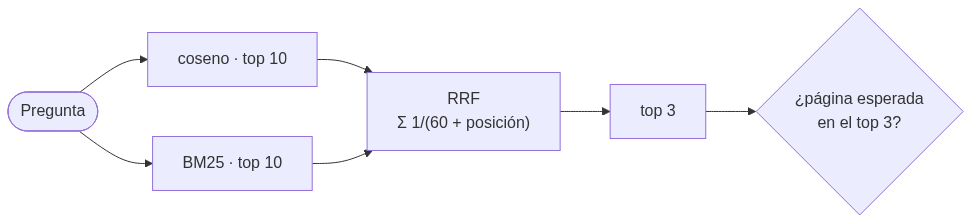

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    Q(["Pregunta"]) --> V["coseno · top 10"] & B["BM25 · top 10"]
    V & B --> F["RRF<br/>Σ 1/(60 + posición)"] --> K["top 3"]
    K --> H{"¿página esperada<br/>en el top 3?"}
```

</details>

`BM25Retriever` es un *runnable*: con LangSmith activo crearía una traza por pregunta. `tracing_context(enabled=False)` las desactiva solo en este bloque.

In [ ]:
import csv
import re

from langchain_community.retrievers import BM25Retriever
from langsmith import tracing_context

with open("../datasets/acme_questions.csv", encoding="utf-8") as file:
    questions = list(csv.DictReader(file))
answerable = [row for row in questions if row["source"]]

bm25 = BM25Retriever.from_documents(chunks, k=10, preprocess_func=lambda text: re.findall(r"\w+", text.lower()))


def rrf(question, k=3, constant=60):
    """Fusiona las listas de coseno y BM25 por posición."""
    scores, by_text = {}, {}
    for ranked in (vector_store.similarity_search(question, k=10), bm25.invoke(question)):
        for position, doc in enumerate(ranked, 1):
            by_text[doc.page_content] = doc
            scores[doc.page_content] = scores.get(doc.page_content, 0) + 1 / (constant + position)
    return [by_text[text] for text in sorted(scores, key=scores.get, reverse=True)[:k]]


def hit(docs, row):
    return any(doc.metadata["source"] == row["source"] and str(doc.metadata["page"]) == row["page"] for doc in docs)


retrievers = {
    "coseno": lambda question: vector_store.similarity_search(question, k=3),
    "bm25": lambda question: bm25.invoke(question)[:3],
    "rrf": rrf,
}
with tracing_context(enabled=False):
    hits = {name: [hit(search(row["question"]), row) for row in answerable] for name, search in retrievers.items()}

for name, results in hits.items():
    print(f"{name:7} {sum(results)}/{len(results)} aciertos en el top 3")

¿En qué preguntas falla cada uno? Las filas muestran solo las preguntas donde al menos uno se equivoca:

In [ ]:
for index, row in enumerate(answerable):
    marks = {name: "✓" if results[index] else "✗" for name, results in hits.items()}
    if "✗" in marks.values():
        print(row["id"], "  ".join(f"{name} {mark}" for name, mark in marks.items()), "·", row["question"])

Con estos 26 fragmentos y este modelo, coseno acierta 15 de 19, BM25 16 y RRF 17. Cada método falla en preguntas distintas. Coseno no encuentra «codeudor» ni «otro banco»: una palabra exacta y poco frecuente pesa poco en el significado de toda la frase. BM25 se pierde cuando la pregunta usa otras palabras que el documento. RRF recupera lo mejor de ambos, pero no todo: q20 («en dólares») falla en los tres, porque el documento dice «pesos colombianos (COP)» y nunca menciona dólares.

Son solo 19 preguntas: una diferencia de 2 aciertos es una pista, no una conclusión. En la semana 6 mediremos las respuestas completas con LangSmith.

**¿Y las preguntas sin respuesta?** Un índice siempre devuelve algo. Comparamos el puntaje del mejor fragmento de las preguntas sin respuesta con el de las que sí la tienen:

In [ ]:
def best_score(question):
    return vector_store.similarity_search_with_score(question, k=1)[0][1]


for row in questions:
    if not row["source"]:
        print(row["id"], round(best_score(row["question"]), 3), row["question"])
print("Mínimo entre las que tienen respuesta:", round(min(best_score(row["question"]) for row in answerable), 3))

Las preguntas sin respuesta obtienen puntajes **más altos** que el mínimo de las que sí la tienen: hablan de crédito, tarjetas y tasas, y se parecen a muchos fragmentos. Un umbral de puntaje no separa «no está» de «está». Por eso la regla del *system prompt* y la revisión de las respuestas siguen siendo necesarias.

## Práctica breve

1. Cambia la pregunta de seguimiento de la sección 2 por *«¿Y eso me lo reportan a las centrales de riesgo?»*. ¿Recupera bien sin reformular?
2. Llama a `conversational_rag` con `history=[]` y la pregunta *«¿Y cuántas veces puedo hacerlo?»*. ¿Qué escribe el paso de reformulación cuando no hay conversación?
3. En la sección 8, cambia `k=3` por `k=5` en los tres recuperadores. ¿Cuántos aciertos gana cada uno? ¿Cuánto contexto más le llegaría a Claude?
4. Pasa la pregunta q20 por `queries = query_model.invoke(...)` de la sección 5 y mide si alguna versión recupera la página esperada.

Continúa con [L9](L9-Memory.ipynb): un agente que guarda la conversación y escribe su propia búsqueda.

## Referencias

**Learning LangChain**, Mayo Oshin y Nuno Campos, O'Reilly, capítulo 3: [`b-rewrite.py`](https://github.com/langchain-ai/learning-langchain/blob/master/ch3/py/b-rewrite.py) (*rewrite-retrieve-read*, secciones 3 y 4) y [`c-multi-query.py`](https://github.com/langchain-ai/learning-langchain/blob/master/ch3/py/c-multi-query.py) (varias consultas, `retriever.batch` y unión sin repetidos, sección 5). El libro genera cinco preguntas y las separa por líneas; aquí son tres, con salida estructurada.

**AI Engineering**, Chip Huyen, capítulo 6: reescritura de consultas y búsqueda híbrida.

**RRF**: Cormack, Clarke y Büttcher, *Reciprocal Rank Fusion outperforms Condorcet and individual Rank Learning Methods*, SIGIR 2009.

- [RAG en LangChain](https://docs.langchain.com/oss/python/langchain/rag) · [Mensajes](https://docs.langchain.com/oss/python/langchain/messages)
- [BM25Retriever](https://docs.langchain.com/oss/python/integrations/retrievers/bm25)